<a href="https://colab.research.google.com/github/2Bert0/previsao-atraso-entregas-ml/blob/main/Previs%C3%A3o_entrega_pedido.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
Path to dataset files: /kaggle/input/brazilian-ecommerce


In [ ]:
import os
import pandas as pd

orders = pd.read_csv(os.path.join(path, "olist_orders_dataset.csv"))
items = pd.read_csv(os.path.join(path, "olist_order_items_dataset.csv"))
customers = pd.read_csv(os.path.join(path, "olist_customers_dataset.csv"))
products = pd.read_csv(os.path.join(path, "olist_products_dataset.csv"))

# Filtra pedidos efetivamente entregues com data estimada válida
entregues = orders.dropna(
    subset=["order_delivered_customer_date", "order_estimated_delivery_date"]
).copy()

entregues["data_entrega"] = pd.to_datetime(
    entregues["order_delivered_customer_date"]
)
entregues["data_estimada"] = pd.to_datetime(
    entregues["order_estimated_delivery_date"]
)

# 1 = atrasou (entregue após a data estimada), 0 = no prazo ou antecipado
entregues["atrasou"] = (
    entregues["data_entrega"] > entregues["data_estimada"]
).astype(int)

print("Total de pedidos entregues:", len(entregues))
print("Proporção de atrasos (%):")
print((entregues["atrasou"].value_counts(normalize=True) * 100).round(2))

Total de pedidos entregues: 96476
Proporção de atrasos (%):
atrasou
0    91.89
1     8.11
Name: proportion, dtype: float64


In [ ]:
sellers = pd.read_csv(os.path.join(path, "olist_sellers_dataset.csv"))

# Junta pedidos com itens (1 linha por pedido para evitar duplicar pedidos no target)
# Pegamos o total de itens, soma de preço, soma de frete e o produto principal
itens_agg = (
    items.groupby("order_id", as_index=False)
    .agg(
        qtd_itens=("order_item_id", "count"),
        valor_produtos=("price", "sum"),
        valor_frete=("freight_value", "sum"),
        product_id=("product_id", "first"),
        seller_id=("seller_id", "first"),
    )
)

df = entregues.merge(itens_agg, on="order_id", how="inner")
df = df.merge(
    customers[["customer_id", "customer_state"]], on="customer_id", how="left"
)
df = df.merge(
    sellers[["seller_id", "seller_state"]], on="seller_id", how="left"
)
df = df.merge(
    products[
        [
            "product_id",
            "product_weight_g",
            "product_length_cm",
            "product_height_cm",
            "product_width_cm",
        ]
    ],
    on="product_id",
    how="left",
)

# Features de tempo disponíveis no momento da compra
df["data_compra"] = pd.to_datetime(df["order_purchase_timestamp"])
df["prazo_estimado_dias"] = (
    df["data_estimada"] - df["data_compra"]
).dt.total_seconds() / 86400
df["dia_semana_compra"] = df["data_compra"].dt.dayofweek
df["mes_compra"] = df["data_compra"].dt.month

# Features de rota e proporção
df["mesma_uf"] = (df["customer_state"] == df["seller_state"]).astype(int)
df["proporcao_frete"] = df["valor_frete"] / (df["valor_produtos"] + 1e-5)

features = [
    "prazo_estimado_dias",
    "dia_semana_compra",
    "mes_compra",
    "qtd_itens",
    "valor_produtos",
    "valor_frete",
    "proporcao_frete",
    "mesma_uf",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm",
]

modelo_df = df[features + ["atrasou"]].copy()
print("Shape do dataset:", modelo_df.shape)
print("\nValores nulos por coluna:")
print(modelo_df.isnull().sum()[modelo_df.isnull().sum() > 0])

Shape do dataset: (96476, 13)

Valores nulos por coluna:
product_weight_g     16
product_length_cm    16
product_height_cm    16
product_width_cm     16
dtype: int64


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

X = modelo_df.drop(columns=["atrasou"])
y = modelo_df["atrasou"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 1. Baseline: Regressão Logística com pesos balanceados
pipe_log = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000)),
])

pipe_log.fit(X_train, y_train)
pred_log = pipe_log.predict(X_test)
prob_log = pipe_log.predict_proba(X_test)[:, 1]

print("=== BASELINE: REGRESSÃO LOGÍSTICA ===")
print("ROC-AUC:", round(roc_auc_score(y_test, prob_log), 4))
print(classification_report(y_test, pred_log, digits=3))

# 2. Modelo baseado em árvores: Random Forest
pipe_rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    (
        "model",
        RandomForestClassifier(
            n_estimators=150,
            max_depth=12,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1,
        ),
    ),
])

pipe_rf.fit(X_train, y_train)
pred_rf = pipe_rf.predict(X_test)
prob_rf = pipe_rf.predict_proba(X_test)[:, 1]

print("=== RANDOM FOREST ===")
print("ROC-AUC:", round(roc_auc_score(y_test, prob_rf), 4))
print(classification_report(y_test, pred_rf, digits=3))

=== BASELINE: REGRESSÃO LOGÍSTICA ===
ROC-AUC: 0.6283
              precision    recall  f1-score   support

           0      0.942     0.577     0.716     17731
           1      0.111     0.599     0.188      1565

    accuracy                          0.579     19296
   macro avg      0.527     0.588     0.452     19296
weighted avg      0.875     0.579     0.673     19296

=== RANDOM FOREST ===
ROC-AUC: 0.7351
              precision    recall  f1-score   support

           0      0.949     0.840     0.891     17731
           1      0.214     0.493     0.298      1565

    accuracy                          0.812     19296
   macro avg      0.582     0.666     0.595     19296
weighted avg      0.890     0.812     0.843     19296



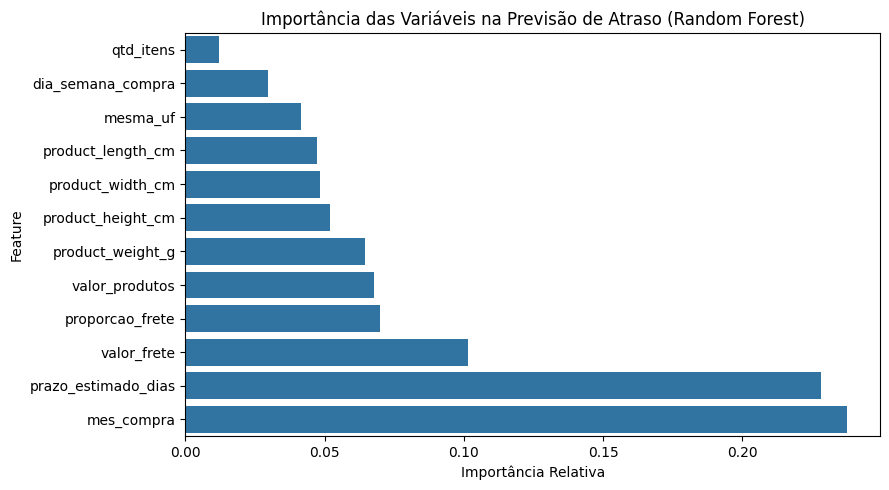

Top 5 variáveis mais importantes:
mes_compra             0.2376
prazo_estimado_dias    0.2284
valor_frete            0.1014
proporcao_frete        0.0697
valor_produtos         0.0677
dtype: float64


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

rf_model = pipe_rf.named_steps["model"]
importancias = pd.Series(
    rf_model.feature_importances_, index=X.columns
).sort_values(ascending=True)

plt.figure(figsize=(9, 5))
sns.barplot(x=importancias.values, y=importancias.index)
plt.title("Importância das Variáveis na Previsão de Atraso (Random Forest)")
plt.xlabel("Importância Relativa")
plt.ylabel("Feature")
plt.tight_layout()

# Salva em alta resolução antes de exibir
plt.savefig("feature_importance_atraso.png", dpi=300, bbox_inches="tight")
plt.show()

print("Top 5 variáveis mais importantes:")
print(importancias.tail(5).sort_values(ascending=False).round(4))

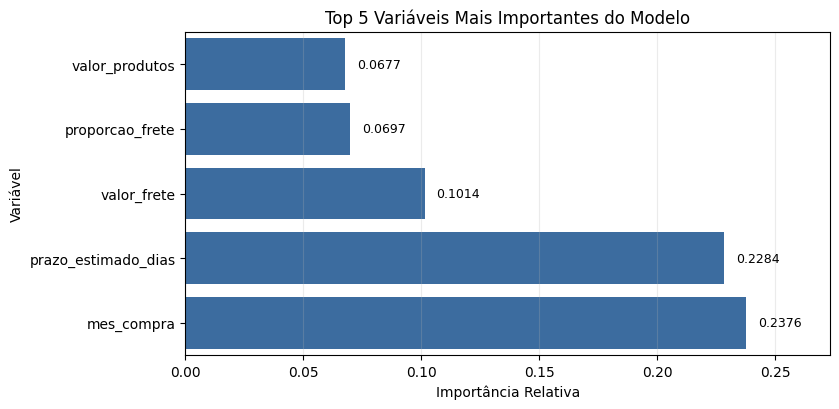

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Reconstroi a série exata da saída obtida no modelo
importancias = pd.Series({
    "mes_compra": 0.2376,
    "prazo_estimado_dias": 0.2284,
    "valor_frete": 0.1014,
    "proporcao_frete": 0.0697,
    "valor_produtos": 0.0677,
}).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8.5, 4.2))

# Gráfico de barras horizontais ordenado do menor para o maior para leitura direta
sns.barplot(x=importancias.values, y=importancias.index, ax=ax, color="#2b6cb0")
ax.set_title("Top 5 Variáveis Mais Importantes do Modelo")
ax.set_xlabel("Importância Relativa")
ax.set_ylabel("Variável")
ax.set_xlim(0, importancias.max() * 1.15)
ax.grid(axis="x", alpha=0.25)

# Adiciona os valores exatos ao lado de cada barra para facilitar a leitura
for i, valor in enumerate(importancias.values):
  ax.text(valor + 0.005, i, f"{valor:.4f}", va="center", fontsize=9)

plt.tight_layout()

# Salva em alta resolução antes de exibir para usar no repositório
plt.savefig("top5_variaveis_importantes.png", dpi=300, bbox_inches="tight")
plt.show()